# Robotization and Wages in the US Manufacturing Industry: data analysis

**Authors:** Nursultan Abukhanov, Aruna Zhakipova · Course project, *Research Methods* (Task 3)

**Research question.** Is a higher share of manufacturing employees exposed to industrial robots in a US state
associated with a different level of real wages in that state's manufacturing sector?

**Hypotheses.** H0: β₁ = 0 · H1: β₁ ≠ 0 (two-sided, α = 0.05), where β₁ is the coefficient on robot exposure in

$$\ln(\text{RealWage}_{it}) = \beta_0 + \beta_1\,\text{Robot}_{it} + \gamma_1 \ln(\text{Emp}_{it}) + \gamma_2 \ln(\text{Estab}_{it}) + \tau_t + \varepsilon_{it}$$

(full notation in [`docs/domain_model.md`](../docs/domain_model.md)).

**What this notebook does.** It reproduces every number and figure of the README from files committed to the
repository, in three stages required by the brief:

1. **Data ingestion & warm-up filtering** – load the raw bootstrap log (`data/raw/test_run.jsonl`), drop the
   cold-start replicates, track failed replicates as a guardrail metric.
2. **Statistical aggregation** – regression models M0, M1, R1–R3 and the bootstrap summary
   (median, p25–p75, p95, p99, 95% CI).
3. **Visualization & export** – publication-ready figures saved to `reports/figures/` as `.pdf` and 300-DPI `.png`.

The heavy lifting lives in `src/` (`process_data.py`, `visualize.py`, `analysis.py`); the notebook imports those
functions, so the notebook and the scripts always give identical results.

> The raw Census and BLS files are not in Git (they are large and public, see `data/README.md`). The state × year
> panel built from them by `python -m src.main --mode full` is committed as `data/processed/panel.csv`, and the
> bootstrap log produced by `python -m src.collector --mode full` as `data/raw/test_run.jsonl`.

## 0. Setup

Fix the random seed and make the project folder importable, so the notebook runs from `notebooks/` or from the repository root.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.analysis import run_models, run_guardrails
from src import process_data as pdx
from src import visualize as viz

cfg = load_config(ROOT / "config.yaml")
SEED = int(cfg["project"]["random_seed"])
np.random.seed(SEED)                      # fixed seed for every random step below
pd.set_option("display.float_format", "{:.4f}".format)
print(f"project root: {ROOT.name} | seed = {SEED}")

project root: repo | seed = 42


## 1. Data ingestion & warm-up filtering

### 1.1 Study panel

One row per state and year (2018–2021). `robot` is the percent of manufacturing employees exposed to robots
(Census ASM), `real_pay` the average annual pay in 2021 dollars (BLS QCEW deflated with CPI-U).

In [2]:
panel = pd.read_csv(ROOT / "data/processed/panel.csv")
print(f"{len(panel)} state-years, {panel['state'].nunique()} states, years {panel['year'].min()}-{panel['year'].max()}")
print("states per year:", panel.groupby("year")["state"].nunique().to_dict())
panel[["state", "year", "robot", "nominal_pay", "real_pay", "employment", "establishments"]].head()

195 state-years, 49 states, years 2018-2021
states per year: {2018: 49, 2019: 49, 2020: 48, 2021: 49}


,state,year,robot,nominal_pay,real_pay,employment,establishments
0,Alabama,2018,28.0000,57068,61582.1780,266798,5566
1,Alabama,2019,32.1000,58532,62037.8712,268948,5677
2,Alabama,2020,25.7000,60387,63223.9951,258328,5773
3,Alabama,2021,28.6000,62595,62595.0000,264500,6050
4,Alaska,2018,NaN,51338,55398.9250,12628,575


**Descriptive statistics.** Reported as Mean ± SD and Median (p25–p75), the formats required for the
README table. Wages are right-skewed (mean above median), which is why the model uses ln(wage).

In [3]:
desc = pdx.describe_panel(panel)
desc[["description", "n", "mean", "sd", "median", "p25", "p75", "min", "max"]]

,description,n,mean,sd,median,p25,p75,min,max
0,Robot exposure (% of employees),192,23.4625,8.3419,22.7500,17.4250,29.5750,6.4000,45.5000
1,Real average annual pay (2021 US$),195,70110.5184,11836.2681,66087.4860,63224.4753,76859.0052,51779.6178,119242.0000
2,Nominal average annual pay (US$),195,67067.3487,11612.7927,63958.0000,59587.0000,72913.0000,47984.0000,119242.0000
3,Manufacturing employment (persons),195,255084.1026,249299.9631,177610.0000,67746.0000,353017.0000,9580.0000,1322455.0000
4,Manufacturing establishments (count),195,7310.6205,7874.6663,4926.0000,2021.5000,8985.0000,575.0000,44706.0000


### 1.2 Bootstrap log and warm-up filtering

`src/collector.py` re-estimated M0 and M1 on 1,020 cluster-bootstrap samples (states drawn with replacement).
Each line of the JSONL log is one replicate of one model. The first 20 replicates are the **warm-up phase**:
they absorb cold-start costs (imports, memory allocation, caches) that inflate the runtime of the first fits,
so they are excluded from all metrics.

In [4]:
raw = pdx.load_log(ROOT / cfg["benchmark"]["output"])
print(raw.groupby(["phase", "model"]).size().rename("records").to_string())

bench = pdx.drop_warmup(raw)
cold = raw[raw["phase"] == "warmup"]["runtime_ms"]
print(f"\nmedian runtime: warm-up {cold.median():.2f} ms vs benchmark {bench['runtime_ms'].median():.2f} ms "
      f"(first fit: {raw['runtime_ms'].iloc[0]:.2f} ms)")

phase      model
benchmark  M0       1000
           M1       1000
warmup     M0         20
           M1         20

median runtime: warm-up 3.76 ms vs benchmark 3.87 ms (first fit: 3.73 ms)


### 1.3 Errors as a guardrail metric (no selection bias)

A replicate whose model cannot be estimated is **counted, not silently dropped**: dropping failures before
averaging would describe only the "easy" samples (selection bias). The threshold is 5%.

In [5]:
rates = pdx.error_rates(bench)
rates["status"] = np.where(rates["error_rate"] <= cfg["guardrails"]["max_bootstrap_error_rate"], "PASS", "FLAG")
rates

,model,n_runs,n_failed,error_rate,status
0,M0,1000,0,0.0000,PASS
1,M1,1000,0,0.0000,PASS


### 1.4 Outlier detection (non-destructive)

Values outside 1.5 × IQR are **flagged, not deleted**. For β₁ an extreme value is a legitimate bootstrap draw;
for runtime it is most likely machine noise (garbage collection, background programs).

In [6]:
bench = pdx.flag_outliers(bench)
bench.groupby("model")[["coef_robot_outlier", "runtime_ms_outlier"]].sum().astype(int)

,coef_robot_outlier,runtime_ms_outlier
model,,
M0,11,100
M1,6,91


## 2. Statistical aggregation

### 2.1 Regression models

* **M0** – baseline: ln(real wage) on robot exposure only.
* **M1** – main model: + ln(employment), ln(establishments) and year effects. **The decision on H0 is made here.**
* **R1–R3** – robustness checks: demeaned exposure, cells flagged "(s)" removed, state fixed effects.

Standard errors are clustered by state (observations of one state over the years are correlated).
`pct_change_per_pp` = 100 × β₁ = % change in real wage per +1 percentage point of robot exposure.

In [7]:
results, m1 = run_models(panel, cfg)
results[["model", "n_obs", "coef", "std_err", "p_value", "ci_low", "ci_high", "pct_change_per_pp", "adj_r2"]]

,model,n_obs,coef,std_err,p_value,ci_low,ci_high,pct_change_per_pp,adj_r2
0,M0,192,-0.0042,0.0021,0.0525,-0.0084,0.0000,-0.4179,0.0441
1,M1,192,-0.0044,0.0021,0.0384,-0.0086,-0.0002,-0.4400,0.3197
2,R1,193,-0.0053,0.0037,0.1571,-0.0127,0.0021,-0.5309,0.2984
3,R2,177,-0.0046,0.0021,0.0346,-0.0088,-0.0003,-0.4573,0.3360
4,R3,192,-0.0000,0.0005,0.9546,-0.0010,0.0010,-0.0029,0.9896


In [8]:
row = results.set_index("model").loc["M1"]
alpha = cfg["model"]["alpha"]
verdict = "REJECT H0" if row["p_value"] < alpha else "FAIL TO REJECT H0"
print(f"{verdict} at alpha = {alpha}: beta_1 = {row['coef']:.4f}, p = {row['p_value']:.4f}, "
      f"95% CI [{row['ci_low']:.4f}, {row['ci_high']:.4f}]")
print(f"=> +1 pp of robot exposure is associated with {row['pct_change_per_pp']:+.2f}% real wage")

REJECT H0 at alpha = 0.05: beta_1 = -0.0044, p = 0.0384, 95% CI [-0.0086, -0.0002]
=> +1 pp of robot exposure is associated with -0.44% real wage


### 2.2 Guardrails (diagnostics)

Guardrails flag problems; they never discard a result. Two flags are expected and explained in the README:
the VIF flag comes from the two size controls (ln employment and ln establishments are correlated at 0.95),
not from robot exposure; heteroskedasticity is handled by the clustered standard errors.

In [9]:
info = {"mode": "full", "withheld_share": 3 / 196}  # 3 of 196 robot cells are withheld by the Census Bureau
guard = run_guardrails(m1, info, panel, cfg)
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = m1.exog
vif = pd.Series({c: variance_inflation_factor(X.values, i) for i, c in enumerate(X.columns) if c != "const"},
                name="VIF")
display(guard)
vif.round(2).to_frame()

,check,value,criterion,status
0,VIF (max over regressors),16.4888,< 10,FLAG
1,Breusch-Pagan p-value,0.0000,> 0.05,FLAG (clustered SE used)
2,Jarque-Bera p-value,0.0823,> 0.05,PASS
3,Min states per year in M1 sample,47.0000,>= 45,PASS
4,Share of withheld robot cells,0.0153,<= 0.1,PASS


,VIF
robot,1.5500
ln_employment,16.4900
ln_establishments,15.2100
year_2019,1.5400
year_2020,1.5300
year_2021,1.6400


### 2.3 Bootstrap summary

For β₁ the 1,000 replicates *are* the bootstrap distribution, so its 95% CI is the 2.5th–97.5th percentile
(percentile bootstrap). For runtime, the 95% CI of the median is obtained by resampling the runtimes (seed 42).
The table is saved to `data/processed/metrics_summary.csv`.

In [10]:
summary = pdx.summarize(bench, seed=SEED)
out_dir = ROOT / "data/processed"
summary.to_csv(out_dir / "metrics_summary.csv", index=False, float_format="%.6f")
bench.to_csv(out_dir / "benchmark_clean.csv", index=False, float_format="%.6f")
desc.to_csv(out_dir / "descriptive_stats.csv", index=False, float_format="%.4f")
summary[["model", "metric", "n", "mean", "sd", "median", "p25", "p75", "p95", "p99", "ci95_low", "ci95_high",
         "n_outliers_iqr", "error_rate"]]

,model,metric,n,mean,sd,median,p25,p75,p95,p99,ci95_low,ci95_high,n_outliers_iqr,error_rate
0,M0,coef_robot,1000,-0.0041,0.0021,-0.0040,-0.0054,-0.0027,-0.0008,0.0005,-0.0083,-0.0002,11,0.0000
1,M0,runtime_ms,1000,3.2236,0.5566,3.0458,2.8491,3.3411,4.4672,5.0480,3.0187,3.0714,100,0.0000
2,M1,coef_robot,1000,-0.0045,0.0021,-0.0044,-0.0059,-0.0031,-0.0009,0.0007,-0.0087,-0.0004,6,0.0000
3,M1,runtime_ms,1000,4.4674,0.7707,4.2237,3.9537,4.6119,6.1608,7.1808,4.1862,4.2561,91,0.0000


The cluster-robust CI of M1 from the regression ([−0.86%, −0.02%]) and the bootstrap CI
([−0.87%, −0.04%]) agree, and the bootstrap interval lies entirely below zero.

## 3. Visualization & export

Three rules of scientific graphics are applied by `src/visualize.py`:

1. **Axes** – every axis names the variable and its unit; wages on a log scale (the model uses ln wage).
2. **Uncertainty** – 95% CI band (fig. 1), full bootstrap distribution with median and 95% CI (fig. 2),
   95% CI error bars (fig. 3).
3. **Accessibility** – colorblind-safe palette plus distinct markers, line styles and hatches for
   black-and-white print.

Each figure is exported to `reports/figures/` as vector `.pdf` and 300-DPI `.png`.

In [11]:
from IPython.display import Image, display

saved = viz.make_all(cfg, panel, bench, ROOT / "reports/figures")
for p in saved:
    print(p.relative_to(ROOT))

reports/figures/fig1_latency_vs_load.pdf
reports/figures/fig1_latency_vs_load.png
reports/figures/fig2_distribution_boxplot.pdf
reports/figures/fig2_distribution_boxplot.png
reports/figures/fig3_coefficients.pdf
reports/figures/fig3_coefficients.png


**Figure 1.** Real wage vs robot exposure (pooled OLS fit with 95% bootstrap CI band).

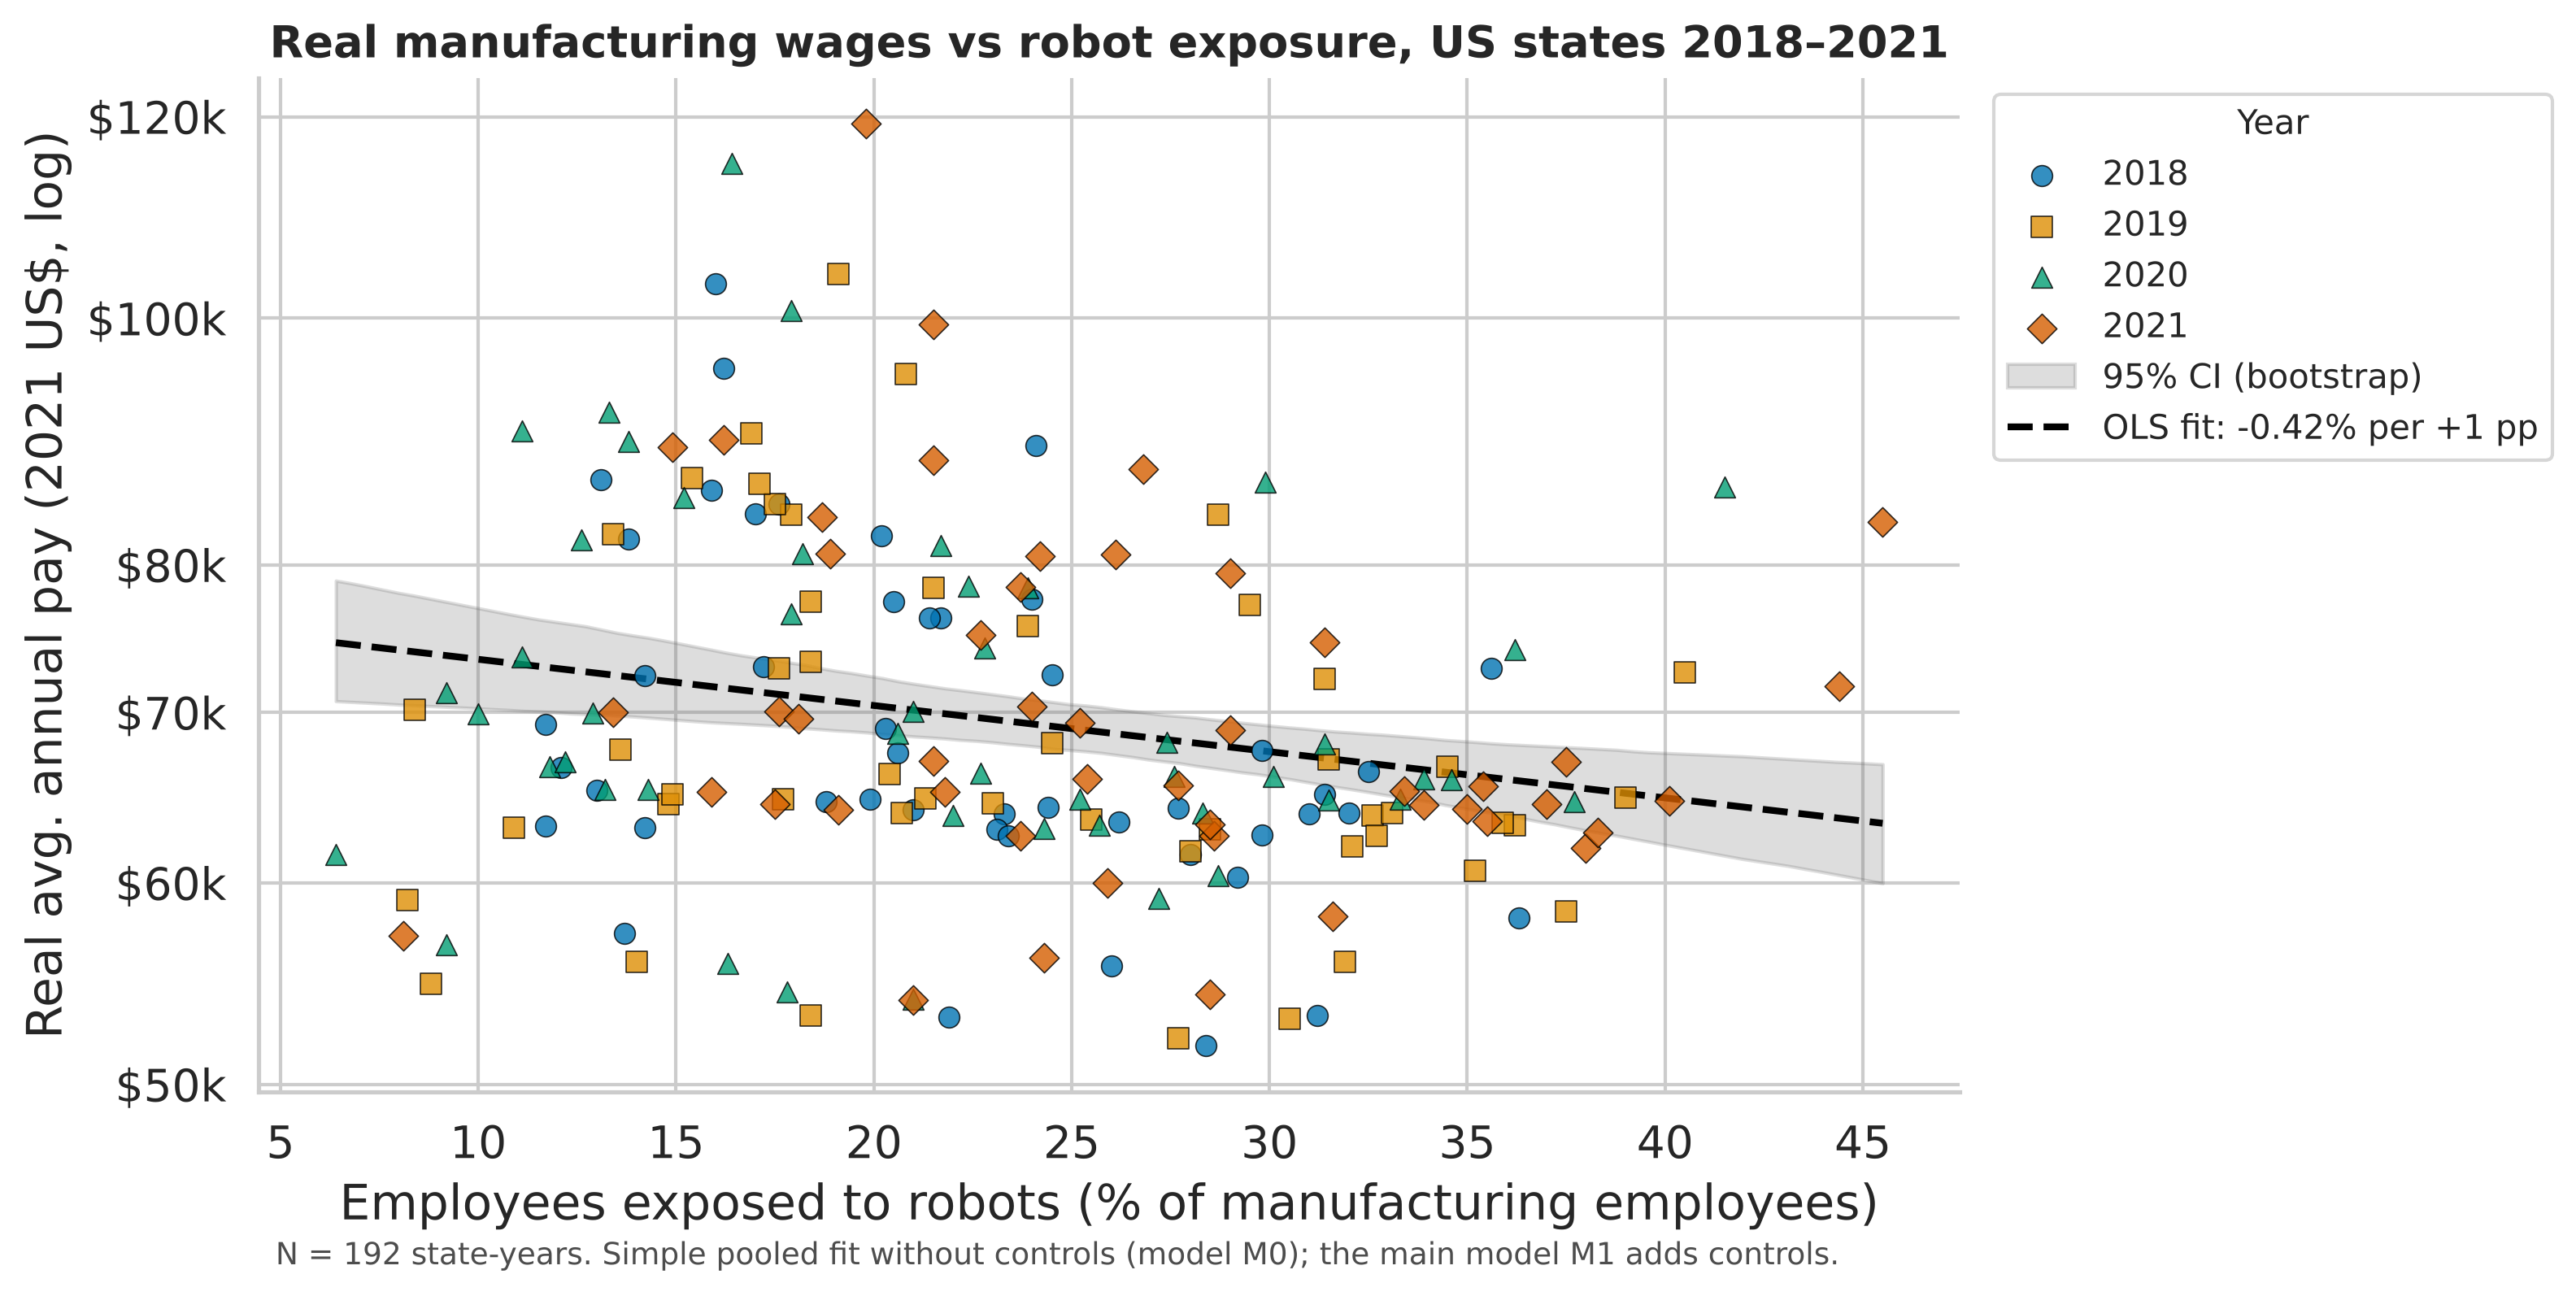

In [12]:
display(Image(filename=str(ROOT / "reports/figures/fig1_latency_vs_load.png"), width=800))

**Figure 2.** Bootstrap distribution of β₁ for the baseline M0 and the main model M1.

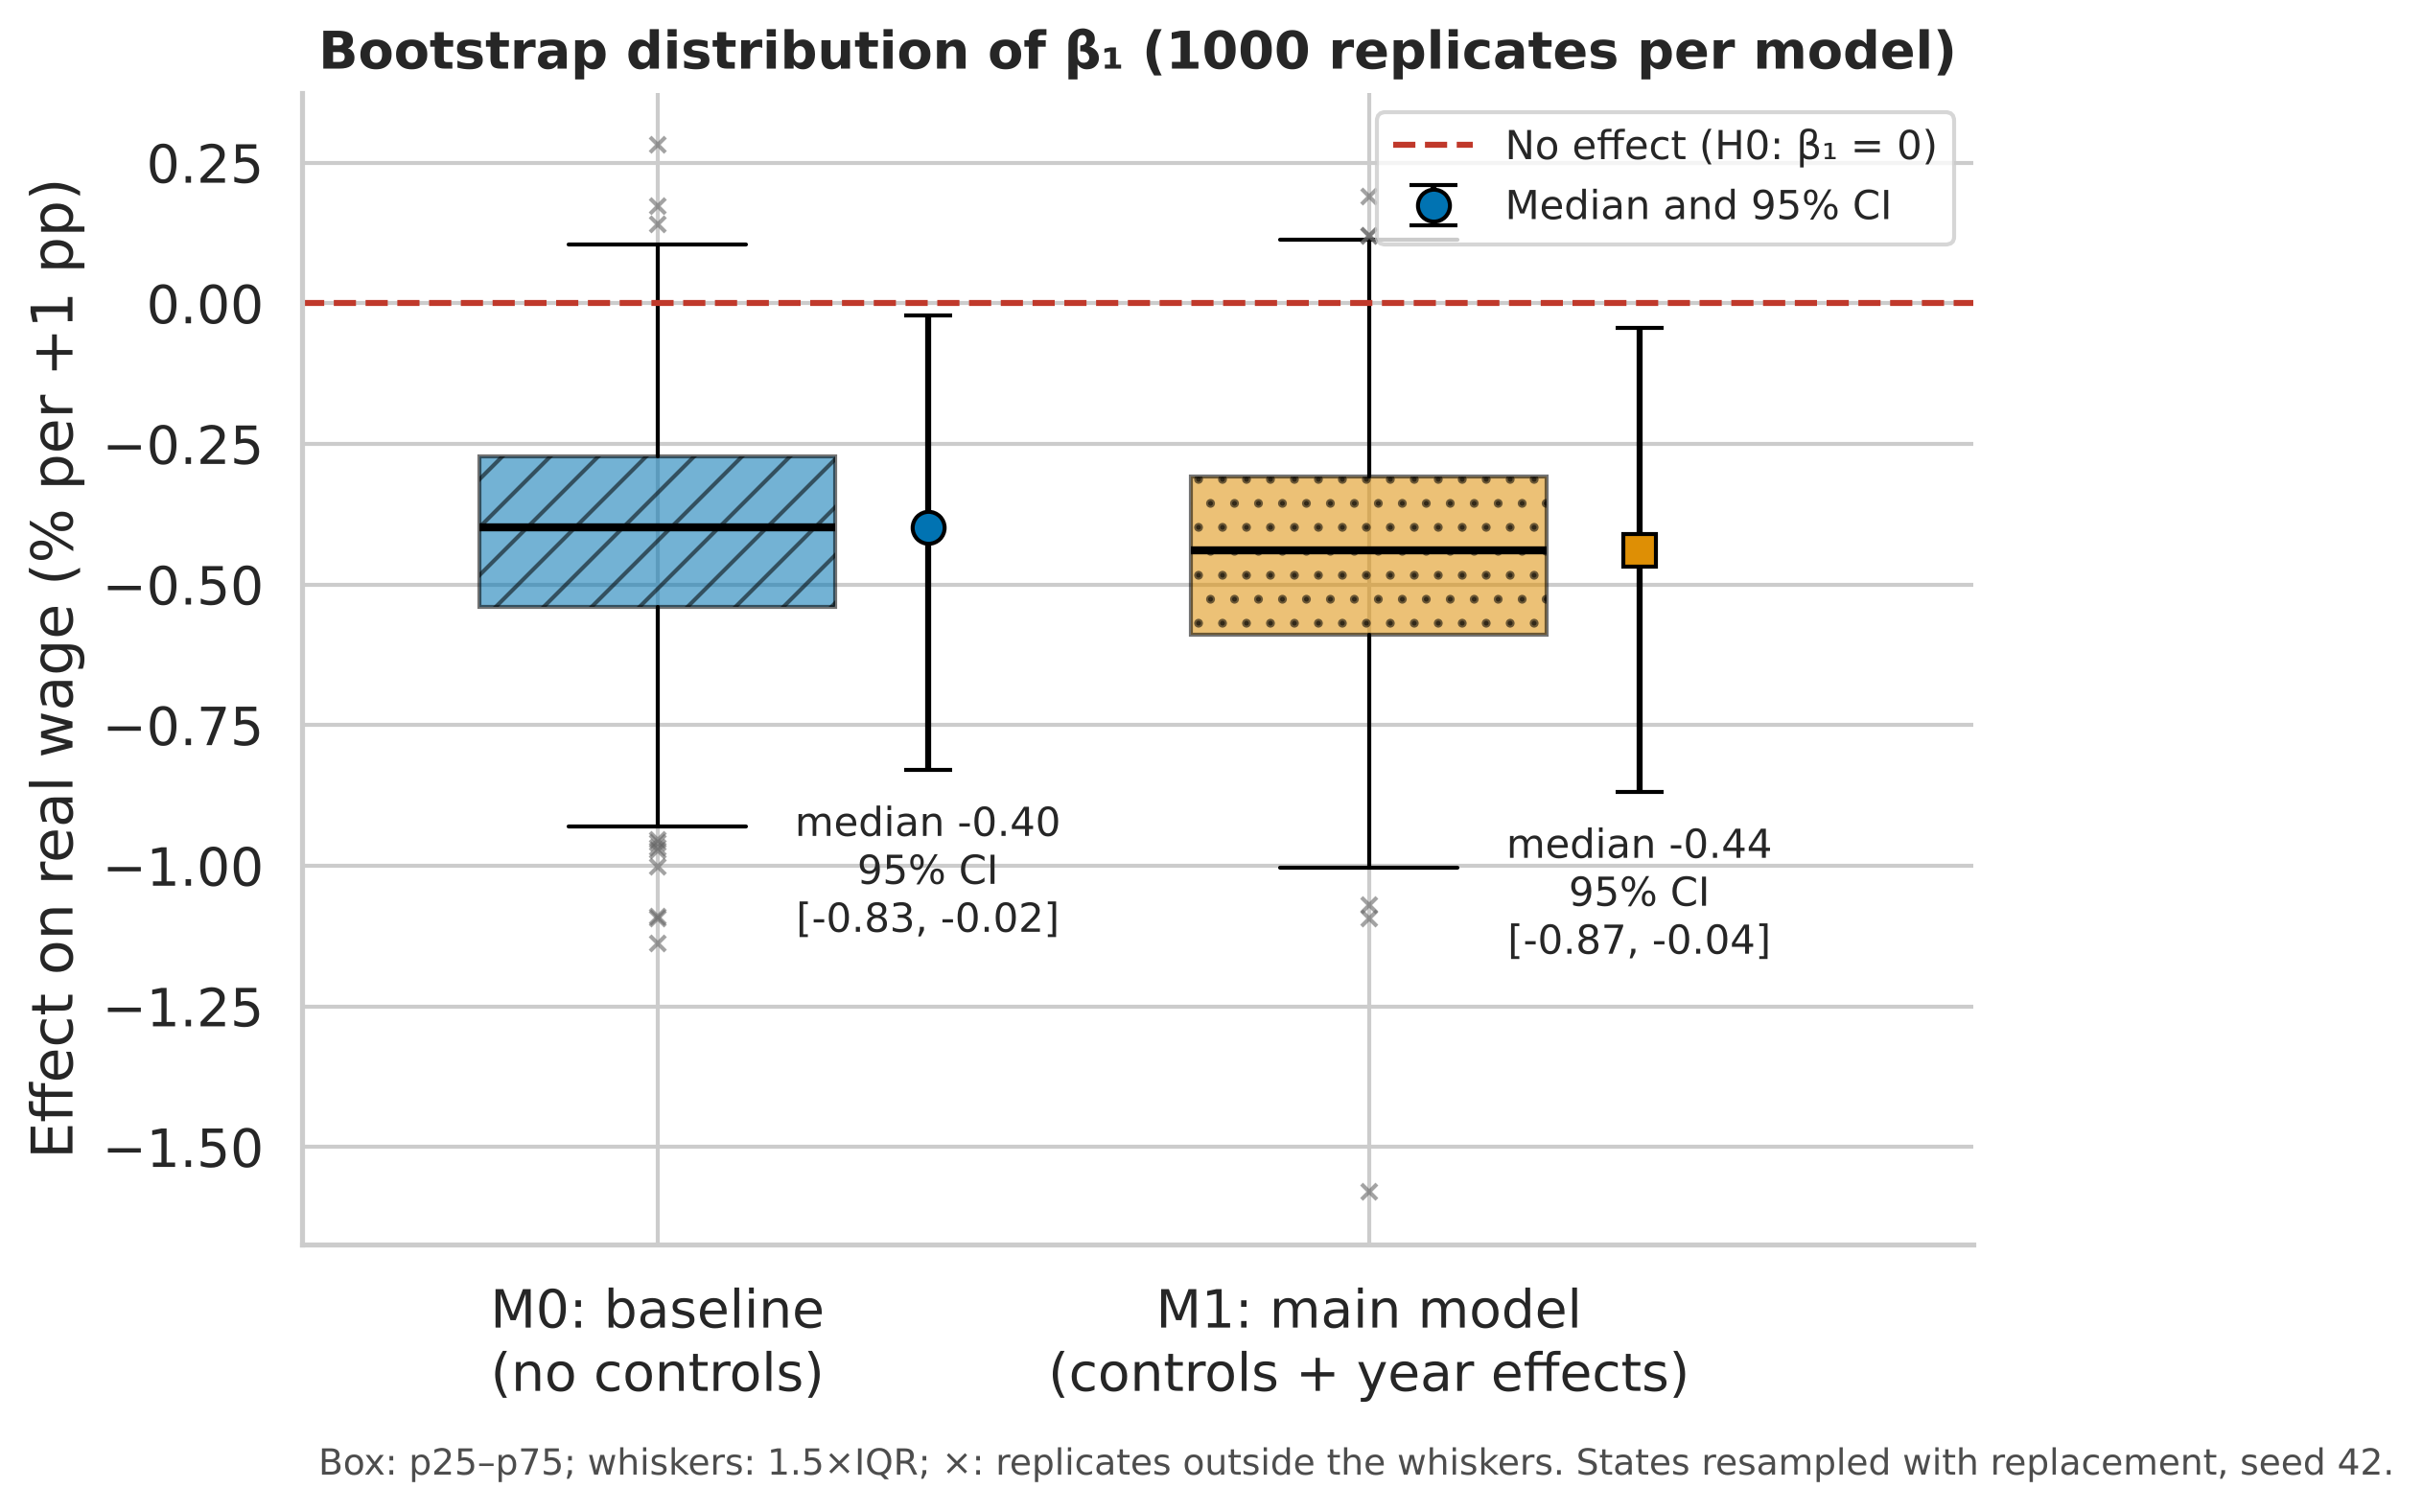

In [13]:
display(Image(filename=str(ROOT / "reports/figures/fig2_distribution_boxplot.png"), width=700))

**Figure 3.** β₁ with 95% CI across all model specifications.

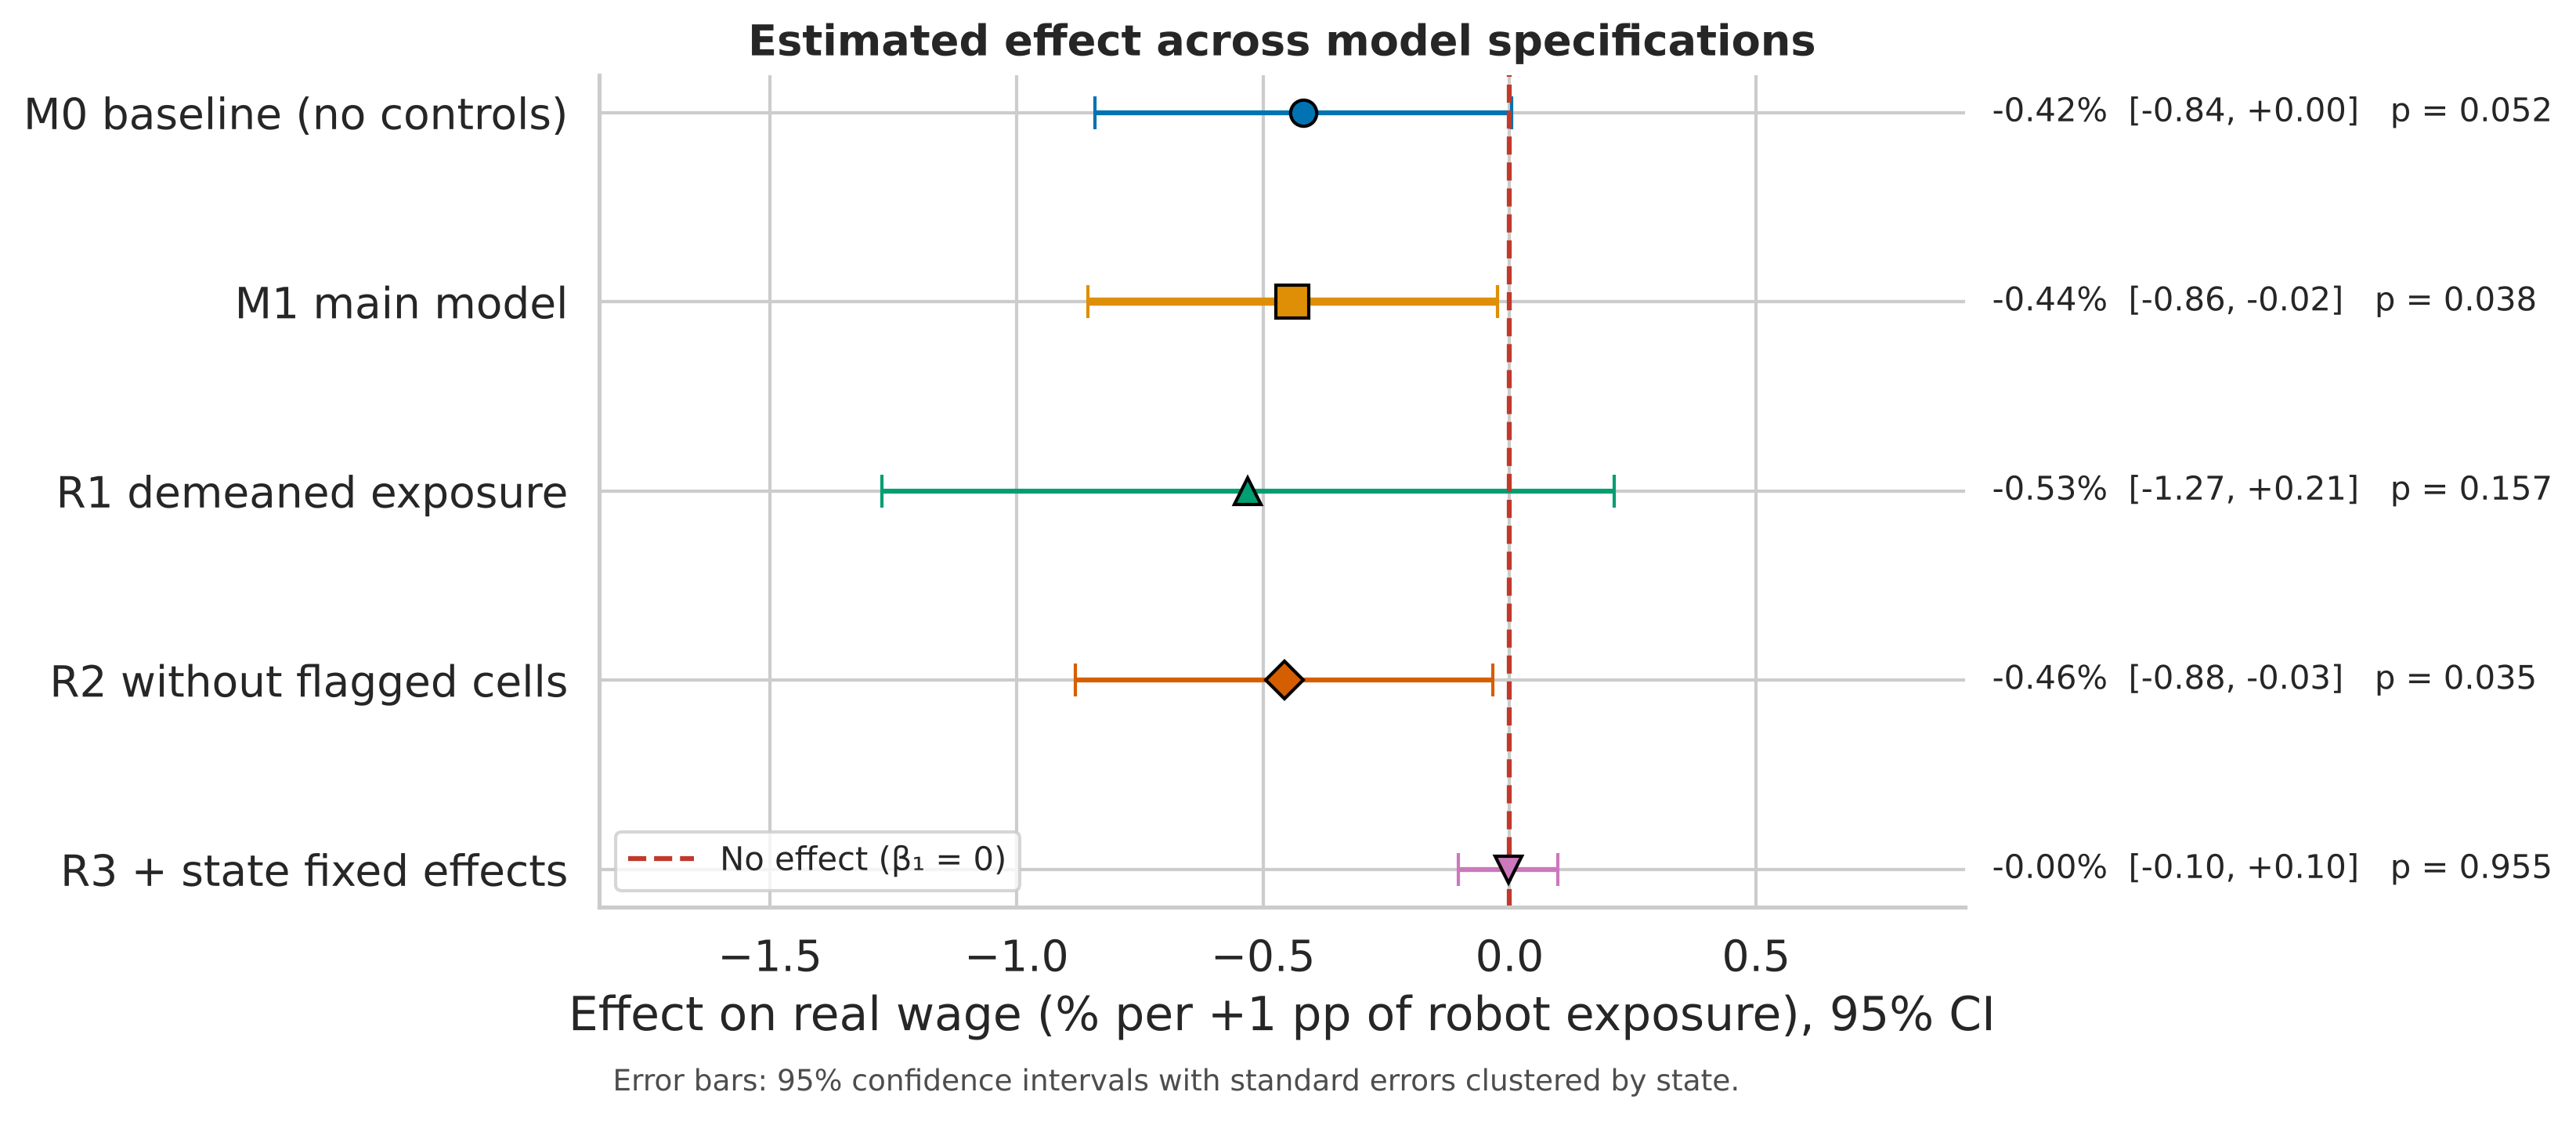

In [14]:
display(Image(filename=str(ROOT / "reports/figures/fig3_coefficients.png"), width=800))

## 4. Conclusion

* In the main model M1 the null hypothesis is **rejected** at α = 0.05: a 1 percentage point higher share of
  employees exposed to robots is associated with about **0.44% lower real manufacturing wages**
  (p = 0.038; cluster-robust 95% CI −0.86% to −0.02%; bootstrap 95% CI −0.87% to −0.04%).
* The estimate is stable across the baseline M0, the main model M1 and R2 (flagged cells removed);
  R1 has the same sign but a wider interval.
* With **state fixed effects (R3)** the coefficient is zero: the association is a **between-state** pattern
  (more robotized states pay less), not a within-state change over 2018–2021, when exposure barely moved.
* The design is observational, so the result is an **association, not a causal effect**.